# Bước 7 — Đánh giá độc lập B0, B1, B2

**Đồ án CV nâng cao · 11/11/2026**

Ba model đã chốt ở bước 6 được chấm trên ba bộ ảnh chưa dùng để train hay chọn tham số:

| Bộ | Ảnh | Câu hỏi |
|---|---|---|
| DigiFace test | 200 người mới, ảnh tổng hợp; thêm query che hình chữ nhật | Kết quả validation có giữ được trên người mới cùng loại ảnh không? |
| ROF | Ảnh người nổi tiếng thật: rõ mặt, khẩu trang, kính râm | Fine-tune trên ảnh tổng hợp có giúp hay làm hại trên ảnh thật? |
| MFR2 | 848 cặp ảnh thật, có khẩu trang | Hai ảnh có cùng một người không (xác minh 1:1)? |

Mọi lựa chọn (model, ngưỡng, cách tiền xử lý, cách sinh che, cách tính chỉ số) được ghi vào `khoa_cau_hinh_buoc7.json` **trước khi** mở ảnh test, và không đổi theo kết quả.

## 1. Khóa cấu hình

- **Model:** B0 = InceptionResnetV1 pretrained VGGFace2; B1, B2 = `huan_luyen/checkpoints_full/*_best_encoder.pt` (SHA-256 ghi trong file khóa).
- **Ngưỡng:** mỗi model dùng ngưỡng đã chọn trên DigiFace validation (FPIR ≤ 5%). Không chọn lại ngưỡng trên test.
- **Tiền xử lý:** DigiFace và MFR2 dùng cách A (resize thẳng 160×160, quy tắc P5). ROF báo hai cách đã định trước: **A** (resize thẳng crop có sẵn, cách chính để so model) và **B** (chạy lại MTCNN như ứng dụng webcam; không thấy đúng một mặt thì tính là nhận sai).
- **Che trên DigiFace test:** đúng thuật toán của validation, mỗi query một vùng che cố định theo seed, gallery không che.
- **Chỉ số:** DIR/FPIR tại ngưỡng đã khóa; Rank-1; với ROF thêm "điểm DET" là DIR khi chỉnh ngưỡng để FPIR = 5% trên chính ROF, chỉ để so model, không phải ngưỡng dùng thật. MFR2: AUC, EER, độ chính xác tại ngưỡng đã khóa. CI 95% bằng bootstrap theo người (ghép cặp giữa các model), 2.000 lần.

File khóa đã có thì notebook chỉ kiểm lại cho khớp, không ghi đè.

In [1]:
from __future__ import annotations
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import os, sys, json, hashlib, time, gc, platform, importlib.metadata, warnings
warnings.filterwarnings('ignore', message='IProgress not found')
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch
from facenet_pytorch import InceptionResnetV1, MTCNN
from facenet_pytorch.models.mtcnn import fixed_image_standardization


def find_root():
    options = [Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    options += [Path.cwd(), *Path.cwd().parents]
    for p in options:
        if (p / 'ban_giao_nhom/danh_gia_test/Danh_gia_doc_lap_B0_B1_B2.ipynb').is_file():
            return p.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc đặt CV_PROJECT_ROOT')


ROOT = find_root()
HERE = ROOT / 'ban_giao_nhom/danh_gia_test'
OUT = HERE / 'notebook_outputs'
TAB, FIG, CACHE = OUT / 'tables', OUT / 'figures', OUT / 'cache'
for p in [OUT, TAB, FIG, CACHE]:
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'ban_giao_nhom/huan_luyen'))
from tai_model import load_encoder
START = time.perf_counter()
SEED = 20261028
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
PROT = ROOT / 'ban_giao_nhom/protocol/notebook_outputs/tables'
CKPT = ROOT / 'ban_giao_nhom/huan_luyen/checkpoints_full'


def sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            h.update(b)
    return h.hexdigest()


def digest(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, ensure_ascii=False, default=str).encode()).hexdigest()


def save(d, name):
    d.to_csv(TAB / (name + '.csv'), index=False, encoding='utf-8-sig', float_format='%.17g')
    return d


def jwrite(x, path):
    Path(path).write_text(json.dumps(x, ensure_ascii=False, indent=2, default=str), encoding='utf-8')


def vn(x, d=0):
    return f'{x:,.{d}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(x):
    return vn(100 * x, 2) + '%'


def finish(fig, name):
    for ext in ['png', 'svg']:
        fig.savefig(FIG / (name + '.' + ext), bbox_inches='tight', dpi=160)
    display(fig); plt.close(fig)


plt.rcParams.update({'font.family': 'Arial', 'figure.dpi': 110, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': .6})
COLORS = {'B0': '#8a8984', 'B1': '#2a78d6', 'B2': '#eb6834'}
MODELS = ['B0', 'B1', 'B2']

# ---- Khóa cấu hình: chỉ đọc checkpoint, bảng protocol và kết quả validation; chưa mở ảnh test ----
step5 = json.loads((ROOT / 'ban_giao_nhom/danh_gia_b0/notebook_outputs/execution_summary.json').read_text())
model_lock = {'B0': {'source': 'facenet-pytorch InceptionResnetV1 pretrained=vggface2',
                     'validation_threshold': step5['threshold_A'], 'validation_DIR': step5['DIR_A']}}
for b in ['B1', 'B2']:
    payload = torch.load(CKPT / f'{b}_best_encoder.pt', map_location='cpu', weights_only=True)
    model_lock[b] = {'file': f'ban_giao_nhom/huan_luyen/checkpoints_full/{b}_best_encoder.pt',
                     'sha256': sha(CKPT / f'{b}_best_encoder.pt'), 'epoch': payload['epoch'],
                     'run_fingerprint': payload['run_fingerprint'],
                     'validation_threshold': payload['metrics']['threshold'], 'validation_DIR': payload['metrics']['DIR']}
    del payload
aug_contract = json.loads((ROOT / 'ban_giao_nhom/augmentation/notebook_outputs/augmentation_pilot_contract.json').read_text(encoding='utf-8'))
prep = json.loads((ROOT / 'ban_giao_nhom/preprocessing/notebook_outputs/preprocessing_candidate_config.json').read_text(encoding='utf-8'))
LOCK = {
    'version': 'step7_independent_test_v1',
    'models': model_lock,
    'inputs_sha256': {n: sha(PROT / f) for n, f in [('digiface_roles', '05_image_roles_draft.csv'),
                                                     ('rof_roles', '07_rof_image_roles_draft.csv'),
                                                     ('external_roles', '07_external_image_roles_draft.csv'),
                                                     ('mfr2_pairs', '08_mfr2_official_pairs_preserved.csv')]},
    'preprocessing': {'DigiFace': 'A_direct_resize', 'MFR2': 'A_direct_resize (ảnh gốc đã 160x160)',
                      'ROF': {'A_direct_resize': 'cách chính để so model',
                              'B_mtcnn_redetect': 'cách của ứng dụng; không đúng một mặt = nhận sai'},
                      'A': 'EXIF, RGB (alpha -> nền trắng), PIL bilinear 160x160, (x-127.5)/128 một lần',
                      'B_config': {k: prep['redetect_candidate'][k] for k in ['image_size', 'margin', 'min_face_size', 'thresholds', 'factor']},
                      'B_face_policy': prep['failure_policy']},
    'digiface_test_occlusion': {'augmentation': aug_contract['augmentation'],
                                'implementation_sha256': aug_contract['implementation_sha256'],
                                'spec': "make_spec(image_id, -1, 'test', force=True), chỉ query; gallery không che"},
    'rof_roles': 'gallery (3 ảnh rõ/người, 144 người quen), known_query, unknown_query (36 người lạ); bỏ ineligible và gallery_group_reserve',
    'metrics': {'open_set': 'template = trung bình embedding L2 rồi chuẩn hóa lại; DIR = known query top-1 đúng và score >= ngưỡng; '
                            'FPIR = unknown query có score >= ngưỡng; người không đăng ký được vẫn ở mẫu số',
                'rof_det_point': 'ngưỡng chọn trên toàn bộ unknown ROF sao cho FPIR <= 5%, DIR lớn nhất; chỉ để so model',
                'mfr2': 'cosine từng cặp; AUC, EER, accuracy/TAR/FAR tại ngưỡng validation',
                'bootstrap': {'repetitions': 2000, 'seed': SEED, 'unit': 'người (known/unknown lấy mẫu riêng); MFR2: cặp'}},
}
LOCK_PATH = HERE / 'khoa_cau_hinh_buoc7.json'
if LOCK_PATH.exists():
    saved_lock = json.loads(LOCK_PATH.read_text(encoding='utf-8'))
    assert {k: v for k, v in saved_lock.items() if k != 'locked_at_utc'} == json.loads(json.dumps(LOCK, default=str)), \
        'Cấu hình khác file khóa: không được đổi model/ngưỡng/cách chấm sau khi đã khóa'
    LOCK_STATUS = 'file khóa có sẵn, khớp'
else:
    jwrite({**LOCK, 'locked_at_utc': datetime.now(timezone.utc).isoformat()}, LOCK_PATH)
    LOCK_STATUS = 'vừa ghi file khóa'
LOCK_SHA = sha(LOCK_PATH)
THRESHOLDS = {m: float(model_lock[m]['validation_threshold']) for m in MODELS}
ENV = {'python': platform.python_version(), 'torch': torch.__version__,
       'facenet_pytorch': importlib.metadata.version('facenet-pytorch'), 'device': DEVICE,
       'gpu': torch.cuda.get_device_name(0) if DEVICE.startswith('cuda') else None}
display(pd.DataFrame([{'model': m, 'epoch': model_lock[m].get('epoch', '–'), 'ngưỡng validation': round(THRESHOLDS[m], 6),
                       'DIR validation': pct(model_lock[m]['validation_DIR'])} for m in MODELS]))
display(Markdown(f'**File khóa:** `{LOCK_PATH.relative_to(ROOT).as_posix()}` ({LOCK_STATUS}), SHA-256 `{LOCK_SHA[:16]}…`'))

,model,epoch,ngưỡng validation,DIR validation
0,B0,–,0.693074,"57,16%"
1,B1,3,0.531435,"93,49%"
2,B2,4,0.525244,"93,49%"


**File khóa:** `ban_giao_nhom/danh_gia_test/khoa_cau_hinh_buoc7.json` (file khóa có sẵn, khớp), SHA-256 `f7daf94a463cfabf…`

Thuật toán che chép nguyên văn từ notebook augmentation; ô sau kiểm SHA của nó với hợp đồng augmentation.

In [2]:
def make_spec(image_id, epoch, partition, force=False):
    seed=int(hashlib.sha256(f"{AUG['seed']}|{partition}|{epoch}|{image_id}".encode()).hexdigest()[:16],16)
    rng=np.random.default_rng(seed)
    applied=bool(force or rng.random()<AUG['train_probability'])
    kind=AUG['kinds'][int(rng.integers(len(AUG['kinds'])))] if applied else 'none'
    box=[0,0,0,0];fill=0
    if applied:
        box=np.array(AUG['boxes'][kind],dtype=int)+rng.integers(-4,5,size=4)
        box=np.clip(box,0,160).tolist()
        fill=int(rng.choice(AUG['fill_values']))
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    return {'image_id':image_id,'epoch':int(epoch),'partition':partition,'seed':str(seed),
            'applied':applied,'kind':kind,'x1':box[0],'y1':box[1],'x2':box[2],'y2':box[3],
            'fill_gray':fill,'mask_pixels':area,'frame_pixels':160*160,
            'mask_fraction_frame':area/(160*160),
            'variant_id':'VAR_'+hashlib.sha256(f'{image_id}|{seed}|{kind}|{box}|{fill}'.encode()).hexdigest()[:24]}

def apply_spec(pixels,spec):
    if pixels.dtype!=np.uint8 or pixels.shape!=(160,160,3):raise ValueError('Expected uint8 RGB160')
    mask=np.zeros((160,160),dtype=np.uint8)
    if bool(spec['applied']):mask[int(spec['y1']):int(spec['y2']),int(spec['x1']):int(spec['x2'])]=1
    if int(mask.sum())!=int(spec['mask_pixels']):raise ValueError('Mask area does not match metadata')
    result=pixels.copy();result[mask.astype(bool)]=int(spec['fill_gray'])
    return result,mask

## 2. Danh sách ảnh test

Lấy đúng vai trò ảnh từ các bảng protocol (bước 3). Mọi ảnh được băm SHA-256 và so với bảng trước khi dùng.

In [3]:
NB_CELLS = json.loads((HERE / 'Danh_gia_doc_lap_B0_B1_B2.ipynb').read_text(encoding='utf-8'))['cells']
COMMON_SRC = next(''.join(c['source']) for c in NB_CELLS
                  if c['cell_type'] == 'code' and ''.join(c['source']).startswith('def make_spec'))
assert hashlib.sha256(COMMON_SRC.encode()).hexdigest() == aug_contract['implementation_sha256']
AUG = aug_contract['augmentation']
for n, f in [('digiface_roles', '05_image_roles_draft.csv'), ('rof_roles', '07_rof_image_roles_draft.csv'),
             ('external_roles', '07_external_image_roles_draft.csv'), ('mfr2_pairs', '08_mfr2_official_pairs_preserved.csv')]:
    assert sha(PROT / f) == LOCK['inputs_sha256'][n], f'Bảng {f} đã đổi sau khi khóa'

R = pd.read_csv(PROT / '05_image_roles_draft.csv', dtype=str, keep_default_na=False)
DT = R[R.partition.eq('test')].sort_values('image_id').reset_index(drop=True)
train_val_ids = set(R[R.partition.isin(['train', 'val'])].canonical_identity)
assert len(DT) == 8000 and not set(DT.canonical_identity) & train_val_ids
DT_Q = DT[DT.role.isin(['known_query', 'unknown_query'])].reset_index(drop=True)
DT_SPEC = pd.DataFrame([make_spec(r.image_id, -1, 'test', force=True) for r in DT_Q.itertuples()])
assert DT_SPEC.applied.all() and DT_SPEC.mask_fraction_frame.between(.15, .4).all()
save(DT_SPEC, '01_digiface_test_query_occlusion_specs')

RO = pd.read_csv(PROT / '07_rof_image_roles_draft.csv', dtype=str, keep_default_na=False)
RO = RO[RO.role.isin(['gallery', 'known_query', 'unknown_query'])].sort_values('image_id').reset_index(drop=True)
EX = pd.read_csv(PROT / '07_external_image_roles_draft.csv', dtype=str, keep_default_na=False)
MF = EX[EX.source.eq('MFR2')].sort_values('image_id').reset_index(drop=True)
MF['rel'] = MF.path.str.replace('data/raw/mfr2/mfr2/', '', regex=False)
PAIRS = pd.read_csv(PROT / '08_mfr2_official_pairs_preserved.csv', dtype=str, keep_default_na=False)
PAIRS['same'] = PAIRS.same_person.eq('True')
assert PAIRS.a.isin(MF.rel).all() and PAIRS.b.isin(MF.rel).all()

ALL = pd.concat([DT.assign(dataset='DigiFace test'), RO.assign(dataset='ROF'), MF.assign(dataset='MFR2')], ignore_index=True)
assert ALL.image_id.is_unique
with ThreadPoolExecutor(max_workers=6) as pool:
    ok = list(pool.map(lambda r: sha(ROOT / r.path) == r.sha256, ALL.itertuples()))
assert all(ok), 'Có ảnh khác SHA trong protocol'

summary_rows = []
for name, frame in [('DigiFace test', DT), ('ROF', RO)]:
    for (role, cond), g in frame.groupby(['role', 'condition']):
        summary_rows.append({'bộ': name, 'vai trò': role, 'điều kiện': cond, 'ảnh': len(g), 'người': g.canonical_identity.nunique()})
summary_rows.append({'bộ': 'DigiFace test', 'vai trò': 'query che (tạo thêm)', 'điều kiện': 'hình chữ nhật', 'ảnh': len(DT_SPEC), 'người': DT_Q.canonical_identity.nunique()})
summary_rows.append({'bộ': 'MFR2', 'vai trò': 'ảnh trong 848 cặp (424 cùng người)', 'điều kiện': 'khẩu trang / không', 'ảnh': len(MF), 'người': MF.canonical_identity.nunique()})
COHORT = save(pd.DataFrame(summary_rows), '02_test_cohort')
display(COHORT)
display(Markdown(f'Đã băm và đối chiếu **{vn(len(ALL))} ảnh**. Người DigiFace test không trùng train/validation.'))

,bộ,vai trò,điều kiện,ảnh,người
0,DigiFace test,gallery,synthetic_unannotated,300,100
1,DigiFace test,known_query,synthetic_unannotated,3700,100
2,DigiFace test,unknown_query,synthetic_unannotated,4000,100
3,ROF,gallery,clean,432,144
4,ROF,known_query,clean,2693,144
5,ROF,known_query,masked,178,47
6,ROF,known_query,sunglasses,1432,126
7,ROF,unknown_query,clean,775,36
8,ROF,unknown_query,masked,20,8
9,ROF,unknown_query,sunglasses,276,29


Đã băm và đối chiếu **14.075 ảnh**. Người DigiFace test không trùng train/validation.

## 3. Tiền xử lý

Cách A đọc ảnh giống hệt lúc train. Cách B (chỉ ROF) chạy MTCNN với cấu hình bước 4: thấy đúng một mặt thì cắt mặt 160×160, không thấy hoặc thấy nhiều mặt thì ghi lại trạng thái và ảnh đó không có embedding (query tính là nhận sai; ảnh gallery thiếu thì template dùng các ảnh còn lại).

In [4]:
def rgb_image(path):
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(source)
        if 'A' in im.getbands():
            rgba = im.convert('RGBA')
            if (np.asarray(rgba.getchannel('A')) < 255).any():
                im = Image.alpha_composite(Image.new('RGBA', rgba.size, (255, 255, 255, 255)), rgba)
        return im.convert('RGB')


def rgb160(row):
    return np.asarray(rgb_image(ROOT / row.path).resize((160, 160), Image.Resampling.BILINEAR), dtype=np.uint8).copy()


def face_dispatch(boxes):
    if boxes is None:
        return 'no_face'
    try:
        boxes = np.asarray(boxes, dtype=np.float64)
    except (TypeError, ValueError):
        return 'invalid_boxes'
    if len(boxes) == 0:
        return 'no_face'
    if boxes.ndim != 2 or boxes.shape[1] != 4 or not np.isfinite(boxes).all():
        return 'invalid_boxes'
    if len(boxes) > 1:
        return 'multiple_faces'
    return 'single_face'


BCFG = LOCK['preprocessing']['B_config']
mtcnn = MTCNN(image_size=BCFG['image_size'], margin=BCFG['margin'], min_face_size=BCFG['min_face_size'],
              thresholds=BCFG['thresholds'], factor=BCFG['factor'], keep_all=True, post_process=True, device=DEVICE).eval()


def redetect(row):
    im = rgb_image(ROOT / row.path)
    with torch.inference_mode():
        boxes, _ = mtcnn.detect(im)
        status = face_dispatch(boxes)
        if status != 'single_face':
            return status, None
        t = mtcnn.extract(im, np.asarray(boxes, dtype=np.float32), save_path=None)[0].cpu()
    return status, (t * 128 + 127.5).round().clamp(0, 255).to(torch.uint8).permute(1, 2, 0).numpy()


pix_fp = digest({'lock': LOCK_SHA, 'ids': ALL[['image_id', 'sha256']].to_csv(index=False), 'pillow': Image.__version__,
                 'facenet': ENV['facenet_pytorch'], 'v': 1})
pix_path = CACHE / 'pixels.npz'
prep_start = time.perf_counter()
if pix_path.exists() and json.loads((CACHE / 'pixels_meta.json').read_text())['fingerprint'] == pix_fp \
        and sha(pix_path) == json.loads((CACHE / 'pixels_meta.json').read_text())['sha256']:
    with np.load(pix_path, allow_pickle=False) as z:
        PIX_A, PIX_B, B_STATUS = z['A'], z['B'], z['B_status'].tolist()
    PIX_MODE = 'matching_cache'
else:
    records = list(ALL.itertuples())
    with ThreadPoolExecutor(max_workers=6) as pool:
        PIX_A = np.stack(list(pool.map(rgb160, records)))
    rof_rows = list(RO.itertuples())
    PIX_B = np.zeros((len(RO), 160, 160, 3), dtype=np.uint8); B_STATUS = []
    for i, r in enumerate(rof_rows):
        status, pixels = redetect(r); B_STATUS.append(status)
        if pixels is not None:
            PIX_B[i] = pixels
    np.savez(pix_path, A=PIX_A, B=PIX_B, B_status=np.array(B_STATUS))
    jwrite({'fingerprint': pix_fp, 'sha256': sha(pix_path)}, CACHE / 'pixels_meta.json')
    PIX_MODE = 'computed_now'
INDEX = {x: i for i, x in enumerate(ALL.image_id)}
RO['b_status'] = B_STATUS
del mtcnn; gc.collect(); torch.cuda.empty_cache() if DEVICE.startswith('cuda') else None

B_TABLE = save(RO.groupby(['role', 'condition']).b_status.value_counts().unstack(fill_value=0).reset_index(), '03_rof_mtcnn_status')
display(B_TABLE)
display(Markdown(f'Tiền xử lý: `{PIX_MODE}`, {time.perf_counter() - prep_start:.0f} giây. '
                 f'Cách B thấy đúng một mặt ở **{pct(np.mean(np.array(B_STATUS) == "single_face"))}** ảnh ROF.'))

b_status,role,condition,multiple_faces,no_face,single_face
0,gallery,clean,0,14,418
1,known_query,clean,2,94,2597
2,known_query,masked,0,50,128
3,known_query,sunglasses,3,85,1344
4,unknown_query,clean,1,37,737
5,unknown_query,masked,0,4,16
6,unknown_query,sunglasses,1,25,250


Tiền xử lý: `matching_cache`, 4 giây. Cách B thấy đúng một mặt ở **94,56%** ảnh ROF.

## 4. Trích embedding

Mỗi model trích embedding 512 chiều cho: DigiFace test (ảnh gốc và query che), ROF theo cách A và B, ảnh MFR2. Embedding được lưu cache theo SHA của model và ảnh.

In [5]:
def embed_array(model, pixels, batch=256):
    out = []
    with torch.inference_mode():
        for s in range(0, len(pixels), batch):
            x = fixed_image_standardization(torch.from_numpy(np.array(pixels[s:s + batch], copy=True)).permute(0, 3, 1, 2).float())
            out.append(model(x.to(DEVICE)).cpu().numpy().astype(np.float32))
    return np.concatenate(out)


dt_idx = np.array([INDEX[x] for x in DT.image_id])
dtq_idx = np.array([INDEX[x] for x in DT_Q.image_id])
spec_by_id = {r['image_id']: r for r in DT_SPEC.to_dict('records')}
occ_pixels = np.stack([apply_spec(PIX_A[INDEX[x]], spec_by_id[x])[0] for x in DT_Q.image_id])
ro_idx = np.array([INDEX[x] for x in RO.image_id])
mf_idx = np.array([INDEX[x] for x in MF.image_id])
b_ok = np.array(B_STATUS) == 'single_face'

EMB = {}
emb_start = time.perf_counter()
for m in MODELS:
    fp = digest({'pix': pix_fp, 'model': model_lock[m], 'v': 1})
    path = CACHE / f'emb_{m}.npz'
    meta_path = CACHE / f'emb_{m}_meta.json'
    if path.exists() and meta_path.exists() and json.loads(meta_path.read_text())['fingerprint'] == fp \
            and sha(path) == json.loads(meta_path.read_text())['sha256']:
        with np.load(path, allow_pickle=False) as z:
            EMB[m] = {k: z[k] for k in z.files}
        continue
    model = load_encoder(m, device=DEVICE)
    if m != 'B0':
        assert model.checkpoint_info['run_fingerprint'] == model_lock[m]['run_fingerprint']
    rofB = np.zeros((len(RO), 512), dtype=np.float32)
    rofB[b_ok] = embed_array(model, PIX_B[b_ok])
    EMB[m] = {'dt': embed_array(model, PIX_A[dt_idx]), 'dt_occ': embed_array(model, occ_pixels),
              'rofA': embed_array(model, PIX_A[ro_idx]), 'rofB': rofB, 'mfr2': embed_array(model, PIX_A[mf_idx])}
    np.savez(path, **EMB[m]); jwrite({'fingerprint': fp, 'sha256': sha(path)}, meta_path)
    del model; gc.collect(); torch.cuda.empty_cache() if DEVICE.startswith('cuda') else None
for m in MODELS:
    for k, e in EMB[m].items():
        assert np.isfinite(e).all()
        norms = np.linalg.norm(e, axis=1)
        assert np.allclose(norms[norms > 0], 1, atol=1e-4)
display(Markdown(f'Embedding 3 model xong sau {time.perf_counter() - emb_start:.0f} giây.'))

Embedding 3 model xong sau 1 giây.

## 5. Hàm chấm chung

Một hàm chấm open-set cho cả DigiFace test và ROF: template mỗi người = trung bình embedding gallery (L2) rồi chuẩn hóa lại; người không còn ảnh gallery nào thì không đăng ký được, nhưng query của họ vẫn ở mẫu số. Query không có embedding (cách B thất bại) tính là không nhận.

In [6]:
def open_set(frame, emb, valid, threshold, gallery_role='gallery'):
    g = frame.role.eq(gallery_role).to_numpy() & valid
    persons = sorted(frame.loc[frame.role.eq(gallery_role), 'canonical_identity'].unique())
    templates, enrolled = [], []
    for p in persons:
        idx = np.flatnonzero(g & frame.canonical_identity.eq(p).to_numpy())
        if len(idx):
            t = emb[idx].mean(axis=0); templates.append(t / np.linalg.norm(t)); enrolled.append(p)
    T = np.stack(templates).astype(np.float32)
    qmask = frame.role.isin(['known_query', 'unknown_query']).to_numpy()
    q = frame.loc[qmask, ['image_id', 'canonical_identity', 'role', 'condition']].reset_index(drop=True)
    qe = emb[qmask]; qv = valid[qmask]
    sim = qe @ T.T; top = sim.argmax(axis=1)
    q['has_embedding'] = qv
    q['is_known'] = q.role.eq('known_query')
    q['top_identity'] = np.where(qv, np.asarray(enrolled)[top], '')
    q['top_score'] = np.where(qv, sim[np.arange(len(q)), top], -np.inf).astype(np.float32)
    q['top1_correct'] = q.is_known & qv & q.top_identity.eq(q.canonical_identity)
    q['accepted'] = q.top_score.to_numpy(np.float32) >= np.float32(threshold)
    q['correct_accepted'] = q.accepted & q.top1_correct
    q['unknown_accepted'] = q.accepted & ~q.is_known
    return q, {'gallery_persons': len(persons), 'enrolled': len(enrolled)}


def summarize(q):
    k = q.is_known; u = ~q.is_known
    return {'known_queries': int(k.sum()), 'unknown_queries': int(u.sum()),
            'DIR': float(q.correct_accepted[k].mean()) if k.any() else np.nan,
            'FPIR': float(q.unknown_accepted[u].mean()) if u.any() else np.nan,
            'rank1': float(q.top1_correct[k].mean()) if k.any() else np.nan}


def det_threshold(q):
    """Ngưỡng cho FPIR <= 5% trên chính bộ này, DIR lớn nhất; chỉ để so model."""
    known = q.is_known.to_numpy(); correct = q.top1_correct.to_numpy()
    scores = q.top_score.to_numpy(np.float32)
    cand = np.r_[np.unique(scores[np.isfinite(scores)]).astype(np.float64), np.inf]
    hit = np.sort(scores[known & correct]); unk = np.sort(scores[~known])
    DIR = (len(hit) - np.searchsorted(hit, cand, side='left')) / known.sum()
    FPIR = (len(unk) - np.searchsorted(unk, cand, side='left')) / (~known).sum()
    ok = FPIR <= .05
    return float(cand[ok & (DIR == DIR[ok].max())].max())


def cluster_arrays(q, known_ids, unknown_ids, col_known='correct_accepted'):
    k = q[q.is_known].groupby('canonical_identity').agg(h=(col_known, 'sum'), n=('image_id', 'size')).reindex(known_ids, fill_value=0).to_numpy(float)
    u = q[~q.is_known].groupby('canonical_identity').agg(h=('unknown_accepted', 'sum'), n=('image_id', 'size')).reindex(unknown_ids, fill_value=0).to_numpy(float)
    return k, u


def paired_bootstrap(qs, known_ids, unknown_ids, reps=2000, col='correct_accepted'):
    """qs: {model: frame}. CI 95% của tỷ lệ `col` trên query người quen (DIR hoặc Rank-1)
    cho từng model và hiệu giữa các model, cùng một mẫu người cho mọi model."""
    arrays = {m: cluster_arrays(q, known_ids, unknown_ids, col_known=col) for m, q in qs.items()}
    rng = np.random.default_rng(SEED); draws = {m: [] for m in qs}
    for _ in range(reps):
        ik = rng.integers(0, len(known_ids), len(known_ids))
        for m, (k, u) in arrays.items():
            draws[m].append(k[ik, 0].sum() / max(k[ik, 1].sum(), 1))
    draws = {m: np.array(v) for m, v in draws.items()}
    rows = []
    for m in qs:
        lo, hi = np.quantile(draws[m], [.025, .975]); rows.append({'so_sánh': m, 'ci95_thấp': lo, 'ci95_cao': hi})
    for a, b in [('B1', 'B0'), ('B2', 'B0'), ('B2', 'B1')]:
        lo, hi = np.quantile(draws[a] - draws[b], [.025, .975])
        point = qs[a].loc[qs[a].is_known, col].mean() - qs[b].loc[qs[b].is_known, col].mean()
        rows.append({'so_sánh': f'{a}-{b}', 'điểm': point, 'ci95_thấp': lo, 'ci95_cao': hi})
    return pd.DataFrame(rows)


# Kiểm hàm chấm: dùng lại embedding B0 validation của bước 5, phải ra đúng số liệu bước 5.
V = R[R.partition.eq('val')].sort_values('image_id').reset_index(drop=True)
with np.load(ROOT / 'ban_giao_nhom/danh_gia_b0/notebook_outputs/cache/embeddings.npz', allow_pickle=False) as z:
    assert z['image_id'].tolist() == V.image_id.tolist(); val_emb = z['emb_A'].copy()
qv, _ = open_set(V.assign(condition='val'), val_emb, np.ones(len(V), bool), THRESHOLDS['B0'])
assert int(qv.correct_accepted.sum()) == round(step5['DIR_A'] * 3700) and int(qv.unknown_accepted.sum()) == 200
display(Markdown('Hàm chấm ra lại đúng B0 validation của bước 5 (2.115 query đúng, 200 người lạ bị nhận nhầm).'))

Hàm chấm ra lại đúng B0 validation của bước 5 (2.115 query đúng, 200 người lạ bị nhận nhầm).

## 6. DigiFace test

Cùng loại ảnh với validation nhưng là 200 người khác. Ngưỡng giữ nguyên từ validation, nên FPIR thực tế có thể lệch khỏi 5%: đó cũng là điều cần đo (ngưỡng có "chuyển" sang người mới được không).

In [7]:
DT_RES, DT_Q_ALL = [], {}
valid_dt = np.ones(len(DT), bool)
for m in MODELS:
    q_base, info = open_set(DT.assign(condition='nền'), EMB[m]['dt'], valid_dt, THRESHOLDS[m])
    # Query che: thay embedding query bằng bản che, gallery giữ nguyên.
    emb_occ = EMB[m]['dt'].copy()
    pos = {x: i for i, x in enumerate(DT.image_id)}
    emb_occ[[pos[x] for x in DT_Q.image_id]] = EMB[m]['dt_occ']
    q_occ, _ = open_set(DT.assign(condition='che'), emb_occ, valid_dt, THRESHOLDS[m])
    DT_Q_ALL[(m, 'nền')], DT_Q_ALL[(m, 'che')] = q_base, q_occ
    for cond, q in [('nền', q_base), ('che', q_occ)]:
        DT_RES.append({'model': m, 'query': cond, 'ngưỡng': THRESHOLDS[m], **summarize(q), 'đăng ký': f"{info['enrolled']}/{info['gallery_persons']}"})
DT_RES = save(pd.DataFrame(DT_RES), '04_digiface_test_results')
known_dt = sorted(DT[DT.role.eq('known_query')].canonical_identity.unique())
unknown_dt = sorted(DT[DT.role.eq('unknown_query')].canonical_identity.unique())
DT_CI = pd.concat([paired_bootstrap({m: DT_Q_ALL[(m, c)] for m in MODELS}, known_dt, unknown_dt).assign(query=c)
                   for c in ['nền', 'che']], ignore_index=True)
save(DT_CI, '04_digiface_test_CI')
show = DT_RES.copy()
for c in ['DIR', 'FPIR', 'rank1']:
    show[c] = (100 * show[c]).round(2)
val_dir = {m: model_lock[m]['validation_DIR'] for m in MODELS}
show['DIR validation'] = [round(100 * val_dir[m], 2) if c == 'nền' else None for m, c in zip(show.model, show['query'])]
display(show[['model', 'query', 'ngưỡng', 'DIR', 'FPIR', 'rank1', 'DIR validation']])
display(DT_CI[DT_CI.so_sánh.str.contains('-')].assign(**{c: lambda d, c=c: (100 * d[c]).round(2) for c in ['điểm', 'ci95_thấp', 'ci95_cao']}))

,model,query,ngưỡng,DIR,FPIR,rank1,DIR validation
0,B0,nền,0.693074,62.92,4.90,86.81,57.16
1,B0,che,0.693074,25.46,2.17,60.24,NaN
2,B1,nền,0.531435,95.38,6.10,97.92,93.49
3,B1,che,0.531435,58.95,4.85,80.68,NaN
4,B2,nền,0.525244,95.24,8.72,98.32,93.49
5,B2,che,0.525244,81.05,6.55,93.24,NaN


,so_sánh,ci95_thấp,ci95_cao,điểm,query
3,B1-B0,29.16,36.08,32.46,nền
4,B2-B0,29.00,36.16,32.32,nền
5,B2-B1,-1.03,0.73,-0.14,nền
9,B1-B0,31.22,35.95,33.49,che
10,B2-B0,53.03,58.33,55.59,che
11,B2-B1,19.86,24.51,22.11,che


## 7. ROF: ảnh che thật

144 người quen (3 ảnh rõ mặt làm gallery) và 36 người lạ. Query chia theo điều kiện: rõ mặt, khẩu trang, kính râm. Người lạ đeo khẩu trang chỉ có 20 ảnh nên FPIR riêng nhóm này rất kém tin cậy; FPIR gộp mọi người lạ được báo kèm.

Ba con số cho mỗi model: DIR/FPIR tại ngưỡng đã khóa (cái ứng dụng thật sẽ gặp nếu dùng nguyên ngưỡng DigiFace), Rank-1 (không cần ngưỡng) và DIR tại điểm DET FPIR = 5% trên ROF (so model công bằng khi ngưỡng DigiFace không còn hợp).

In [8]:
ROF_RES, ROF_Q = [], {}
for pipe, key, valid in [('A', 'rofA', np.ones(len(RO), bool)), ('B', 'rofB', b_ok)]:
    for m in MODELS:
        q, info = open_set(RO, EMB[m][key], valid, THRESHOLDS[m])
        t_det = det_threshold(q)
        q['accepted_det'] = q.top_score.to_numpy(np.float32) >= np.float32(t_det)
        ROF_Q[(pipe, m)] = q
        for cond in ['tất cả', 'clean', 'masked', 'sunglasses']:
            s = q if cond == 'tất cả' else q[q.condition.eq(cond)]
            k = s.is_known
            ROF_RES.append({'cách': pipe, 'model': m, 'điều kiện': cond, **summarize(s),
                            'FPIR gộp': float(q.unknown_accepted[~q.is_known].mean()),
                            'ngưỡng DET': t_det, 'DIR @DET': float((s.accepted_det & s.top1_correct)[k].mean()),
                            'đăng ký': f"{info['enrolled']}/{info['gallery_persons']}"})
ROF_RES = save(pd.DataFrame(ROF_RES), '05_rof_results')
known_ro = sorted(RO[RO.role.eq('known_query')].canonical_identity.unique())
unknown_ro = sorted(RO[RO.role.eq('unknown_query')].canonical_identity.unique())
ci_rows = []
for pipe in ['A', 'B']:
    for cond in ['tất cả', 'clean', 'masked', 'sunglasses']:
        qs = {m: (ROF_Q[(pipe, m)] if cond == 'tất cả' else ROF_Q[(pipe, m)][ROF_Q[(pipe, m)].condition.eq(cond)]) for m in MODELS}
        for metric, col in [('DIR@ngưỡng khóa', 'correct_accepted'), ('Rank-1', 'top1_correct')]:
            ci_rows.append(paired_bootstrap(qs, known_ro, unknown_ro, col=col).assign(cách=pipe, điều_kiện=cond, chỉ_số=metric))
ROF_CI = save(pd.concat(ci_rows, ignore_index=True), '05_rof_CI')
show = ROF_RES[ROF_RES['cách'].eq('A')].copy()
for c in ['DIR', 'FPIR', 'FPIR gộp', 'rank1', 'DIR @DET']:
    show[c] = (100 * show[c]).round(2)
display(Markdown('**Cách A (resize crop có sẵn) — cách chính**'))
display(show[['model', 'điều kiện', 'known_queries', 'unknown_queries', 'DIR', 'FPIR', 'FPIR gộp', 'rank1', 'DIR @DET']])
display(Markdown('Hiệu giữa các model trên ROF (cách A), CI 95% bootstrap theo người. Rank-1 không phụ thuộc ngưỡng nên là phép so chính.'))
display(ROF_CI[ROF_CI['cách'].eq('A') & ROF_CI.so_sánh.str.contains('-')]
        .assign(**{c: lambda d, c=c: (100 * d[c]).round(2) for c in ['điểm', 'ci95_thấp', 'ci95_cao']})
        [['chỉ_số', 'điều_kiện', 'so_sánh', 'điểm', 'ci95_thấp', 'ci95_cao']].sort_values(['chỉ_số', 'điều_kiện'], kind='stable'))

**Cách A (resize crop có sẵn) — cách chính**

,model,điều kiện,known_queries,unknown_queries,DIR,FPIR,FPIR gộp,rank1,DIR @DET
0,B0,tất cả,4303,1071,62.61,0.09,0.09,92.80,77.74
1,B0,clean,2693,775,83.25,0.00,0.09,97.77,92.91
2,B0,masked,178,20,10.67,0.00,0.09,80.34,35.39
3,B0,sunglasses,1432,276,30.24,0.36,0.09,84.99,54.47
4,B1,tất cả,4303,1071,70.95,89.64,89.64,72.23,40.55
5,B1,clean,2693,775,86.41,94.97,89.64,86.85,60.53
6,B1,masked,178,20,32.02,65.00,89.64,34.83,0.56
7,B1,sunglasses,1432,276,46.72,76.45,89.64,49.37,7.96
8,B2,tất cả,4303,1071,66.49,93.46,93.46,67.16,32.91
9,B2,clean,2693,775,81.80,96.77,93.46,82.03,49.54


Hiệu giữa các model trên ROF (cách A), CI 95% bootstrap theo người. Rank-1 không phụ thuộc ngưỡng nên là phép so chính.

,chỉ_số,điều_kiện,so_sánh,điểm,ci95_thấp,ci95_cao
15,DIR@ngưỡng khóa,clean,B1-B0,3.16,1.14,5.30
16,DIR@ngưỡng khóa,clean,B2-B0,-1.45,-4.27,1.12
17,DIR@ngưỡng khóa,clean,B2-B1,-4.60,-6.62,-2.79
27,DIR@ngưỡng khóa,masked,B1-B0,21.35,12.40,30.49
28,DIR@ngưỡng khóa,masked,B2-B0,21.91,13.20,33.34
29,DIR@ngưỡng khóa,masked,B2-B1,0.56,-11.21,12.32
39,DIR@ngưỡng khóa,sunglasses,B1-B0,16.48,11.48,21.45
40,DIR@ngưỡng khóa,sunglasses,B2-B0,11.66,7.16,16.06
41,DIR@ngưỡng khóa,sunglasses,B2-B1,-4.82,-8.02,-1.71
3,DIR@ngưỡng khóa,tất cả,B1-B0,8.34,6.04,10.61


In [9]:
show = ROF_RES[ROF_RES['cách'].eq('B')].copy()
for c in ['DIR', 'FPIR', 'FPIR gộp', 'rank1', 'DIR @DET']:
    show[c] = (100 * show[c]).round(2)
display(Markdown('**Cách B (chạy lại MTCNN như ứng dụng webcam) — ảnh không thấy đúng một mặt tính là nhận sai**'))
display(show[['model', 'điều kiện', 'DIR', 'FPIR gộp', 'rank1', 'DIR @DET', 'đăng ký']])
det = RO[RO.role.ne('gallery')].groupby('condition').b_status.apply(lambda s: (s == 'single_face').mean()).rename('tỷ lệ thấy đúng 1 mặt')
display((100 * det).round(2).to_frame())

**Cách B (chạy lại MTCNN như ứng dụng webcam) — ảnh không thấy đúng một mặt tính là nhận sai**

,model,điều kiện,DIR,FPIR gộp,rank1,DIR @DET,đăng ký
12,B0,tất cả,60.89,0.09,88.84,76.37,144/144
13,B0,clean,82.18,0.09,95.40,91.50,144/144
14,B0,masked,8.43,0.09,56.74,28.65,144/144
15,B0,sunglasses,27.37,0.09,80.52,53.84,144/144
16,B1,tất cả,68.30,85.90,69.42,39.79,144/144
17,B1,clean,84.78,85.90,85.15,59.41,144/144
18,B1,masked,20.79,85.90,24.72,0.00,144/144
19,B1,sunglasses,43.23,85.90,45.39,7.82,144/144
20,B2,tất cả,63.79,89.17,64.42,32.51,144/144
21,B2,clean,79.95,89.17,80.25,49.35,144/144


,tỷ lệ thấy đúng 1 mặt
condition,
clean,96.14
masked,72.73
sunglasses,93.33


## 8. MFR2: xác minh hai ảnh có cùng một người

848 cặp chính thức (424 cùng người, 424 khác người), ảnh đã căn 160×160. Điểm của một cặp là cosine giữa hai embedding. AUC và EER không cần ngưỡng; độ chính xác, TAR (cặp cùng người được chấp nhận) và FAR (cặp khác người bị chấp nhận) đo tại ngưỡng validation của từng model. Ngưỡng đó vốn chọn cho so khớp 1:N với template, nên kết quả tại ngưỡng chỉ mang tính tham khảo. MFR2 không có fold chính thức nên không báo accuracy 10-fold.

In [10]:
rel_pos = {x: i for i, x in enumerate(MF.rel)}
ia = PAIRS.a.map(rel_pos).to_numpy(); ib = PAIRS.b.map(rel_pos).to_numpy()
masked_rel = set(MF.loc[MF.condition.eq('masked'), 'rel'])
PAIRS['loại cặp'] = [('che–che' if (a in masked_rel and b in masked_rel) else
                      'rõ–rõ' if (a not in masked_rel and b not in masked_rel) else 'che–rõ')
                     for a, b in zip(PAIRS.a, PAIRS.b)]
y = PAIRS.same.to_numpy()


def auc_score(s, y):
    order = np.argsort(s, kind='mergesort'); ranks = np.empty(len(s)); ranks[order] = np.arange(1, len(s) + 1)
    # Hạng trung bình cho các giá trị bằng nhau.
    _, inv, cnt = np.unique(s, return_inverse=True, return_counts=True)
    sums = np.bincount(inv, ranks); ranks = (sums / cnt)[inv]
    npos = y.sum(); nneg = len(y) - npos
    return (ranks[y].sum() - npos * (npos + 1) / 2) / (npos * nneg)


def eer(s, y):
    ts = np.unique(s)
    far = np.array([(s[~y] >= t).mean() for t in ts]); frr = np.array([(s[y] < t).mean() for t in ts])
    i = np.argmin(np.abs(far - frr)); return float((far[i] + frr[i]) / 2)


SCORES = {m: (EMB[m]['mfr2'][ia] * EMB[m]['mfr2'][ib]).sum(axis=1) for m in MODELS}
MF_RES = []
for m in MODELS:
    s = SCORES[m]
    for kind in ['tất cả', 'rõ–rõ', 'che–rõ', 'che–che']:
        sel = np.ones(len(s), bool) if kind == 'tất cả' else PAIRS['loại cặp'].eq(kind).to_numpy()
        ss, yy = s[sel], y[sel]; acc = ss >= THRESHOLDS[m]
        MF_RES.append({'model': m, 'loại cặp': kind, 'cặp': int(sel.sum()), 'cùng người': int(yy.sum()),
                       'AUC': auc_score(ss, yy) if 0 < yy.sum() < len(yy) else np.nan,
                       'EER': eer(ss, yy) if 0 < yy.sum() < len(yy) else np.nan,
                       'accuracy@ngưỡng': float((acc == yy).mean()),
                       'TAR@ngưỡng': float(acc[yy].mean()) if yy.any() else np.nan,
                       'FAR@ngưỡng': float(acc[~yy].mean()) if (~yy).any() else np.nan})
MF_RES = save(pd.DataFrame(MF_RES), '06_mfr2_results')
rng = np.random.default_rng(SEED); boot = {m: [] for m in MODELS}
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    for m in MODELS:
        boot[m].append(auc_score(SCORES[m][i], y[i]))
boot = {m: np.array(v) for m, v in boot.items()}
mf_ci = [{'so_sánh': m, 'ci95_thấp': np.quantile(boot[m], .025), 'ci95_cao': np.quantile(boot[m], .975)} for m in MODELS]
for a, b in [('B1', 'B0'), ('B2', 'B0'), ('B2', 'B1')]:
    d = boot[a] - boot[b]
    mf_ci.append({'so_sánh': f'{a}-{b}', 'điểm': auc_score(SCORES[a], y) - auc_score(SCORES[b], y),
                  'ci95_thấp': np.quantile(d, .025), 'ci95_cao': np.quantile(d, .975)})
MF_CI = save(pd.DataFrame(mf_ci), '06_mfr2_AUC_CI')
show = MF_RES.copy()
for c in ['EER', 'accuracy@ngưỡng', 'TAR@ngưỡng', 'FAR@ngưỡng']:
    show[c] = (100 * show[c]).round(2)
show['AUC'] = show.AUC.round(4)
display(show)
display(MF_CI.round(4))

,model,loại cặp,cặp,cùng người,AUC,EER,accuracy@ngưỡng,TAR@ngưỡng,FAR@ngưỡng
0,B0,tất cả,848,424,0.9908,3.30,70.17,40.33,0.00
1,B0,rõ–rõ,69,8,1.0000,0.00,98.55,87.50,0.00
2,B0,che–rõ,383,184,0.9820,4.44,58.75,14.13,0.00
3,B0,che–che,396,232,0.9966,1.26,76.26,59.48,0.00
4,B1,tất cả,848,424,0.9349,14.86,85.38,81.84,11.08
5,B1,rõ–rõ,69,8,0.9980,0.82,91.30,100.00,9.84
6,B1,che–rõ,383,184,0.9322,16.72,80.68,65.76,5.53
7,B1,che–che,396,232,0.9476,11.61,88.89,93.97,18.29
8,B2,tất cả,848,424,0.9441,13.44,86.56,83.25,10.14
9,B2,rõ–rõ,69,8,0.9857,11.99,86.96,100.00,14.75


,so_sánh,ci95_thấp,ci95_cao,điểm
0,B0,0.9849,0.9957,NaN
1,B1,0.9190,0.9500,NaN
2,B2,0.9295,0.9577,NaN
3,B1-B0,-0.0700,-0.0419,-0.0558
4,B2-B0,-0.0608,-0.0332,-0.0467
5,B2-B1,-0.0021,0.0209,0.0092


## 9. Tổng hợp

Hình 1 đặt cạnh nhau DIR của ba model trên mọi bộ: validation (bước 6), DigiFace test, ROF theo điều kiện (cách A, điểm DET để so model trên ảnh thật). Hình 2 là đường ROC trên MFR2.

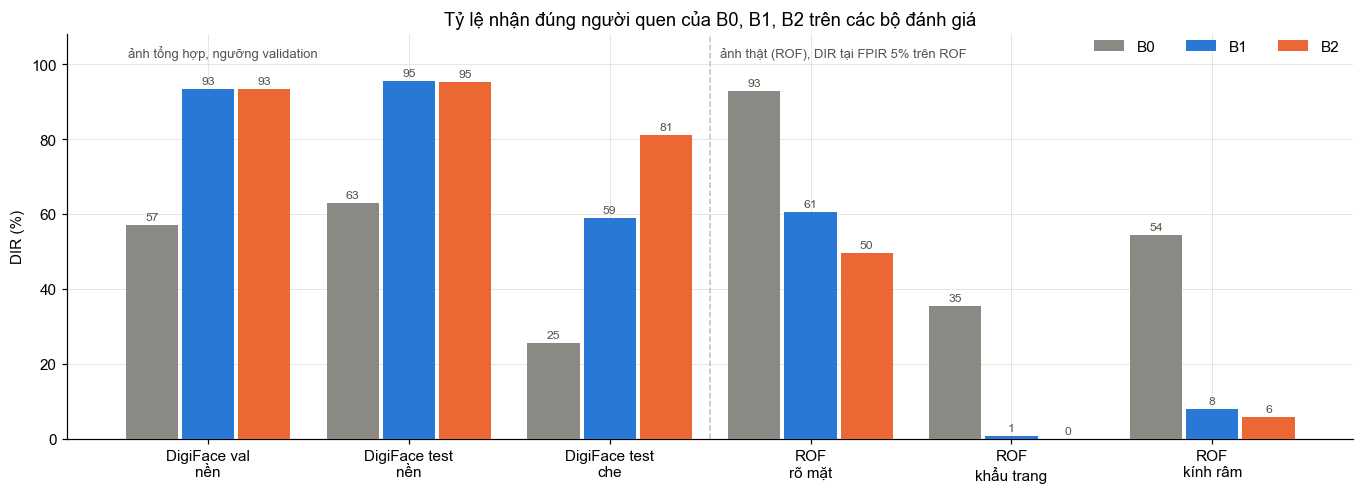

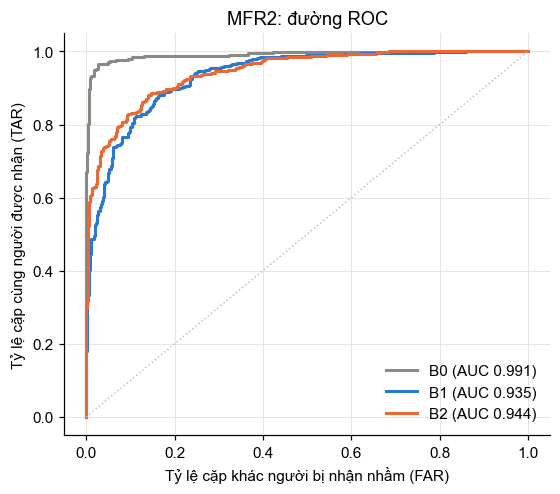

In [11]:
rows = []
for m in MODELS:
    rows.append({'model': m, 'bộ': 'DigiFace val\nnền', 'DIR': model_lock[m]['validation_DIR']})
    for cond, lab in [('nền', 'DigiFace test\nnền'), ('che', 'DigiFace test\nche')]:
        rows.append({'model': m, 'bộ': lab, 'DIR': DT_RES[(DT_RES.model == m) & (DT_RES['query'] == cond)].DIR.iloc[0]})
    for cond, lab in [('clean', 'ROF\nrõ mặt'), ('masked', 'ROF\nkhẩu trang'), ('sunglasses', 'ROF\nkính râm')]:
        rows.append({'model': m, 'bộ': lab, 'DIR': ROF_RES[(ROF_RES['cách'] == 'A') & (ROF_RES.model == m) & (ROF_RES['điều kiện'] == cond)]['DIR @DET'].iloc[0]})
OVER = save(pd.DataFrame(rows), '07_overview_DIR')
groups = list(dict.fromkeys(OVER['bộ']))
fig, ax = plt.subplots(figsize=(12.5, 4.6)); w = .26
for i, m in enumerate(MODELS):
    vals = [100 * OVER[(OVER.model == m) & (OVER['bộ'] == g)].DIR.iloc[0] for g in groups]
    bars = ax.bar(np.arange(len(groups)) + (i - 1) * (w + .02), vals, w, color=COLORS[m], label=m, zorder=3)
    ax.bar_label(bars, fmt='%.0f', fontsize=8, padding=2, color='#52514e')
ax.axvline(2.5, color='#c3c2b7', lw=1, ls='--')
ax.text(2.55, 101, 'ảnh thật (ROF), DIR tại FPIR 5% trên ROF', fontsize=8.5, color='#52514e', va='bottom')
ax.text(-.4, 101, 'ảnh tổng hợp, ngưỡng validation', fontsize=8.5, color='#52514e', va='bottom')
ax.set_xticks(np.arange(len(groups)), groups); ax.set_ylim(0, 108)
ax.set(ylabel='DIR (%)', title='Tỷ lệ nhận đúng người quen của B0, B1, B2 trên các bộ đánh giá')
ax.legend(frameon=False, ncols=3, loc='upper right', bbox_to_anchor=(1, 1.02)); fig.tight_layout(); finish(fig, '01_overview_DIR')

fig, ax = plt.subplots(figsize=(5.2, 4.6))
for m in MODELS:
    s = SCORES[m]; ts = np.r_[np.inf, np.sort(np.unique(s))[::-1]]
    tpr = [(s[y] >= t).mean() for t in ts]; fpr = [(s[~y] >= t).mean() for t in ts]
    ax.plot(fpr, tpr, color=COLORS[m], lw=2, label=f"{m} (AUC {MF_RES[(MF_RES.model == m) & (MF_RES['loại cặp'] == 'tất cả')].AUC.iloc[0]:.3f})")
ax.plot([0, 1], [0, 1], color='#c3c2b7', lw=1, ls=':')
ax.set(xlabel='Tỷ lệ cặp khác người bị nhận nhầm (FAR)', ylabel='Tỷ lệ cặp cùng người được nhận (TAR)', title='MFR2: đường ROC')
ax.legend(frameon=False, loc='lower right'); fig.tight_layout(); finish(fig, '02_mfr2_roc')

In [12]:
def get(df, **kw):
    s = df
    for k, v in kw.items():
        s = s[s[k] == v]
    return s.iloc[0]


ci_rof = lambda cond, comp, metric='Rank-1': get(ROF_CI, cách='A', điều_kiện=cond, so_sánh=comp, chỉ_số=metric)
ci_dt = lambda cond, comp: get(DT_CI, query=cond, so_sánh=comp)
rA = lambda m, cond: get(ROF_RES, cách='A', model=m, **{'điều kiện': cond})
summary = {'checks': 'PASS', 'lock_file': LOCK_PATH.relative_to(ROOT).as_posix(), 'lock_sha256': LOCK_SHA, 'lock_status': LOCK_STATUS,
           'thresholds': THRESHOLDS, 'images_hashed': len(ALL), 'pixel_cache': PIX_MODE,
           'digiface_test': DT_RES.to_dict('records'), 'rof': ROF_RES.to_dict('records'), 'mfr2': MF_RES.to_dict('records'),
           'rof_mtcnn_single_face_rate': float(np.mean(b_ok)), 'environment': ENV,
           'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'elapsed_seconds': time.perf_counter() - START}
jwrite(summary, OUT / 'execution_summary.json')
fmt_ci = lambda r: f"{100 * r['điểm']:+.2f} điểm, CI 95% [{100 * r['ci95_thấp']:+.2f}; {100 * r['ci95_cao']:+.2f}]".replace('.', ',')
mf_all = lambda m: get(MF_RES, model=m, **{'loại cặp': 'tất cả'})
mf_ci = lambda comp: get(MF_CI, so_sánh=comp)
fmt_auc = lambda r: f"{r['điểm']:+.4f}, CI 95% [{r['ci95_thấp']:+.4f}; {r['ci95_cao']:+.4f}]".replace('.', ',')
display(Markdown(f"""## 10. Kết luận

**Ảnh tổng hợp (DigiFace test, 200 người mới, ngưỡng validation).** Kết quả validation giữ được trên người mới. DIR ảnh nền B0 {pct(get(DT_RES, model='B0', query='nền').DIR)}, B1 {pct(get(DT_RES, model='B1', query='nền').DIR)}, B2 {pct(get(DT_RES, model='B2', query='nền').DIR)}; query che B0 {pct(get(DT_RES, model='B0', query='che').DIR)}, B1 {pct(get(DT_RES, model='B1', query='che').DIR)}, B2 {pct(get(DT_RES, model='B2', query='che').DIR)} (B2 − B1 = {fmt_ci(ci_dt('che', 'B2-B1'))}). FPIR thực tế tại ngưỡng validation: {pct(get(DT_RES, model='B0', query='nền').FPIR)} / {pct(get(DT_RES, model='B1', query='nền').FPIR)} / {pct(get(DT_RES, model='B2', query='nền').FPIR)}.

**Ảnh thật (ROF, cách A).** B1 và B2 kém B0 rõ rệt.

- Rank-1 (không cần ngưỡng), mọi query: B0 {pct(rA('B0', 'tất cả').rank1)}, B1 {pct(rA('B1', 'tất cả').rank1)}, B2 {pct(rA('B2', 'tất cả').rank1)}. B1 − B0 = {fmt_ci(ci_rof('tất cả', 'B1-B0'))}; B2 − B0 = {fmt_ci(ci_rof('tất cả', 'B2-B0'))}.
- Rank-1 riêng khẩu trang: B0 {pct(rA('B0', 'masked').rank1)}, B1 {pct(rA('B1', 'masked').rank1)}, B2 {pct(rA('B2', 'masked').rank1)}; kính râm: {pct(rA('B0', 'sunglasses').rank1)} / {pct(rA('B1', 'sunglasses').rank1)} / {pct(rA('B2', 'sunglasses').rank1)}.
- DIR tại FPIR 5% trên ROF: rõ mặt {pct(rA('B0', 'clean')['DIR @DET'])} / {pct(rA('B1', 'clean')['DIR @DET'])} / {pct(rA('B2', 'clean')['DIR @DET'])}; khẩu trang {pct(rA('B0', 'masked')['DIR @DET'])} / {pct(rA('B1', 'masked')['DIR @DET'])} / {pct(rA('B2', 'masked')['DIR @DET'])}; kính râm {pct(rA('B0', 'sunglasses')['DIR @DET'])} / {pct(rA('B1', 'sunglasses')['DIR @DET'])} / {pct(rA('B2', 'sunglasses')['DIR @DET'])}.
- Ngưỡng DigiFace không dùng được cho ảnh thật với B1/B2: FPIR {pct(rA('B0', 'tất cả').FPIR)} / {pct(rA('B1', 'tất cả').FPIR)} / {pct(rA('B2', 'tất cả').FPIR)}. DIR tại ngưỡng khóa của B1/B2 trông cao hơn B0 chỉ vì gần như mọi người lạ cũng được chấp nhận.

**MFR2 (xác minh 1:1).** AUC B0 {mf_all('B0').AUC:.4f}, B1 {mf_all('B1').AUC:.4f}, B2 {mf_all('B2').AUC:.4f}; EER {pct(mf_all('B0').EER)} / {pct(mf_all('B1').EER)} / {pct(mf_all('B2').EER)}. B1 − B0 = {fmt_auc(mf_ci('B1-B0'))}; B2 − B0 = {fmt_auc(mf_ci('B2-B0'))}.

**MTCNN (cách B):** thấy đúng một mặt ở {pct(np.mean(b_ok))} ảnh ROF; ảnh đeo khẩu trang thấp nhất (xem mục 7). Kết luận so model theo cách B giống cách A.

Ảnh ROF/MFR2 là ảnh người nổi tiếng trên mạng, nhãn chưa được nhóm xác minh độc lập. Model, ngưỡng và cách chấm đã khóa trước khi chạy (`{LOCK_PATH.name}`).
"""))

## 10. Kết luận

**Ảnh tổng hợp (DigiFace test, 200 người mới, ngưỡng validation).** Kết quả validation giữ được trên người mới. DIR ảnh nền B0 62,92%, B1 95,38%, B2 95,24%; query che B0 25,46%, B1 58,95%, B2 81,05% (B2 − B1 = +22,11 điểm, CI 95% [+19,86; +24,51]). FPIR thực tế tại ngưỡng validation: 4,90% / 6,10% / 8,72%.

**Ảnh thật (ROF, cách A).** B1 và B2 kém B0 rõ rệt.

- Rank-1 (không cần ngưỡng), mọi query: B0 92,80%, B1 72,23%, B2 67,16%. B1 − B0 = -20,57 điểm, CI 95% [-23,40; -17,78]; B2 − B0 = -25,63 điểm, CI 95% [-29,14; -22,25].
- Rank-1 riêng khẩu trang: B0 80,34%, B1 34,83%, B2 36,52%; kính râm: 84,99% / 49,37% / 43,02%.
- DIR tại FPIR 5% trên ROF: rõ mặt 92,91% / 60,53% / 49,54%; khẩu trang 35,39% / 0,56% / 0,00%; kính râm 54,47% / 7,96% / 5,73%.
- Ngưỡng DigiFace không dùng được cho ảnh thật với B1/B2: FPIR 0,09% / 89,64% / 93,46%. DIR tại ngưỡng khóa của B1/B2 trông cao hơn B0 chỉ vì gần như mọi người lạ cũng được chấp nhận.

**MFR2 (xác minh 1:1).** AUC B0 0.9908, B1 0.9349, B2 0.9441; EER 3,30% / 14,86% / 13,44%. B1 − B0 = -0,0558, CI 95% [-0,0700; -0,0419]; B2 − B0 = -0,0467, CI 95% [-0,0608; -0,0332].

**MTCNN (cách B):** thấy đúng một mặt ở 94,56% ảnh ROF; ảnh đeo khẩu trang thấp nhất (xem mục 7). Kết luận so model theo cách B giống cách A.

Ảnh ROF/MFR2 là ảnh người nổi tiếng trên mạng, nhãn chưa được nhóm xác minh độc lập. Model, ngưỡng và cách chấm đã khóa trước khi chạy (`khoa_cau_hinh_buoc7.json`).


## 11. Đọc kết quả

- **Fine-tune trên DigiFace giúp trên DigiFace nhưng làm hại trên ảnh người thật.** B1/B2 học rất tốt ảnh render (validation và test DigiFace đều khoảng 95%), nhưng mất một phần khả năng phân biệt mặt thật mà B0 có từ VGGFace2: Rank-1 trên ROF và AUC trên MFR2 đều giảm. Nguyên nhân hợp lý nhất là lệch miền giữa ảnh tổng hợp và ảnh thật, cộng với việc fine-tune toàn bộ mạng làm quên đặc trưng cũ.
- **Lợi ích của che nhân tạo (B2 so với B1) chỉ thấy trên ảnh che tổng hợp.** Trên khẩu trang thật của ROF, B2 không hơn B1 rõ ràng, và cả hai đều kém B0.
- **Ngưỡng phải chọn lại theo loại ảnh.** Ngưỡng chọn trên DigiFace làm B1/B2 nhận nhầm phần lớn người lạ trên ảnh thật. Với webcam, ngưỡng phải chọn bằng ảnh webcam phiên 2.
- **Hệ quả cho demo:** với dữ liệu hiện có, **B0** là model nên dùng cho webcam. Muốn fine-tune có ích trên ảnh thật cần dữ liệu train là ảnh thật, hoặc fine-tune nhẹ hơn (chỉ mở vài lớp cuối, LR nhỏ) và chọn checkpoint bằng một tập ảnh thật riêng, không phải ROF/MFR2.

Đây là kết quả âm nhưng trả lời đúng câu hỏi của bước 7. Kết quả được giữ nguyên; cách chấm không bị sửa để cứu B1/B2.

## 12. Đầu ra

- `khoa_cau_hinh_buoc7.json`: cấu hình khóa trước khi chấm test (model, ngưỡng, tiền xử lý, chỉ số).
- `notebook_outputs/tables/`: số liệu từng bộ (`04_*` DigiFace test, `05_*` ROF, `06_*` MFR2, `07_overview_DIR.csv`).
- `notebook_outputs/figures/`: hình cho slide. `notebook_outputs/execution_summary.json`: tóm tắt lượt chạy.
- `notebook_outputs/cache/`: pixel và embedding để chạy lại nhanh; không cần gửi nhóm.